In [29]:

import torch

print("CUDA Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU Name:", torch.cuda.get_device_name(0))
    print("PyTorch Version:", torch.__version__)
else:
    print("GPU is still unavailable. Do not start training yet.")

!nvidia-smi


CUDA Available: True
GPU Name: Tesla T4
PyTorch Version: 2.14.1+cu130
Sun Nov 22 20:51:04 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   60C    P0             31W /   70W |    2269MiB /  15360MiB |      0%      Default |
|                                         |                        |  

In [30]:

from google.colab import drive
from pathlib import Path

# Connect Google Drive
drive.mount('/content/drive')

# Project paths
PROJECT_DIR = Path(
    "/content/drive/MyDrive/NLP_Task3"
)

DATA_DIR = PROJECT_DIR / "dataset" / "processed"

MODEL_DIR = PROJECT_DIR / "pretrained_model"
RESULTS_DIR = PROJECT_DIR / "results"

MODEL_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print("Google Drive connected successfully!")
print("Dataset directory:", DATA_DIR)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Google Drive connected successfully!
Dataset directory: /content/drive/MyDrive/NLP_Task3/dataset/processed


In [31]:

import pandas as pd

# Load the three shared datasets
train_df = pd.read_csv(
    DATA_DIR / "yelp_train_150k_seed42.csv.gz"
)

val_df = pd.read_csv(
    DATA_DIR / "yelp_validation_150k_seed42.csv.gz"
)

test_df = pd.read_csv(
    DATA_DIR / "yelp_test_150k_seed42.csv.gz"
)

print("Datasets loaded successfully!")

print("Training:", train_df.shape)
print("Validation:", val_df.shape)
print("Testing:", test_df.shape)


Datasets loaded successfully!
Training: (120000, 5)
Validation: (15000, 5)
Testing: (15000, 5)


In [32]:

# Label mapping
LABEL2ID = {
    "negative": 0,
    "neutral": 1,
    "positive": 2
}

ID2LABEL = {
    value: key
    for key, value in LABEL2ID.items()
}

# Validate columns
required_columns = [
    "review_id",
    "text",
    "stars",
    "sentiment",
    "label"
]

for name, df in {
    "Train": train_df,
    "Validation": val_df,
    "Test": test_df
}.items():

    assert all(
        col in df.columns
        for col in required_columns
    )

    assert df["text"].notna().all()
    assert df["label"].isin([0, 1, 2]).all()

    print(f"{name}: Validated successfully")

# Preview
display(
    train_df[
        ["text", "stars", "sentiment", "label"]
    ].head(5)
)

print("\nShared dataset is ready for training!")


Train: Validated successfully
Validation: Validated successfully
Test: Validated successfully


,text,stars,sentiment,label
0,This place has drastically changed from our la...,3,neutral,1
1,Worst car wash EVER!! My car wasn't vacuumed ...,1,negative,0
2,The staff was friendly and I enjoyed the atmos...,3,neutral,1
3,Very flavorful ice cream. Did not try anything...,5,positive,2
4,I stumbled upon a micro/ brewery in New Hope a...,4,positive,2



Shared dataset is ready for training!


In [33]:

# Install pretrained model dependencies

!pip -q install transformers==4.48.3 scikit-learn seaborn

print("Libraries installed successfully!")


Libraries installed successfully!


In [34]:

import os
import json
import time
import random
import numpy as np
import torch
import matplotlib.pyplot as plt
import seaborn as sns

from torch.utils.data import Dataset, DataLoader
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    get_linear_schedule_with_warmup
)

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix
)

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# Device configuration
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("PyTorch version:", torch.__version__)
print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: GPU is not enabled.")
    print("Go to Runtime > Change runtime type > T4 GPU")

# Model configuration
MODEL_CHECKPOINT = "distilbert-base-uncased"

NUM_LABELS = 3
MAX_LENGTH = 256

TRAIN_BATCH_SIZE = 16
EVAL_BATCH_SIZE = 32

NUM_EPOCHS = 2
LEARNING_RATE = 2e-5
WEIGHT_DECAY = 0.01

USE_AMP = torch.cuda.is_available()

BEST_MODEL_DIR = MODEL_DIR / "distilbert_yelp_sentiment"

print("\nModel configuration ready!")


PyTorch version: 2.14.1+cu130
Device: cuda
GPU: Tesla T4

Model configuration ready!


In [35]:

# ==========================================
# LOAD PRETRAINED TOKENIZER
# ==========================================

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_CHECKPOINT
)

print("Tokenizer loaded successfully!")

print("Vocabulary size:", tokenizer.vocab_size)
print("Maximum sequence length:", MAX_LENGTH)

# Custom PyTorch Dataset
class YelpSentimentDataset(Dataset):

    def __init__(self, dataframe):

        self.texts = (
            dataframe["text"]
            .astype(str)
            .tolist()
        )

        self.labels = (
            dataframe["label"]
            .astype(int)
            .tolist()
        )

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, index):

        return {
            "text": self.texts[index],
            "label": self.labels[index]
        }


# Dynamic padding collator
def collate_batch(batch):

    texts = [item["text"] for item in batch]

    labels = torch.tensor(
        [item["label"] for item in batch],
        dtype=torch.long
    )

    encoded = tokenizer(
        texts,
        padding=True,
        truncation=True,
        max_length=MAX_LENGTH,
        return_tensors="pt"
    )

    encoded["labels"] = labels

    return encoded


# Create datasets
train_dataset = YelpSentimentDataset(train_df)
val_dataset = YelpSentimentDataset(val_df)
test_dataset = YelpSentimentDataset(test_df)

# Create DataLoaders
train_loader = DataLoader(
    train_dataset,
    batch_size=TRAIN_BATCH_SIZE,
    shuffle=True,
    collate_fn=collate_batch,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=EVAL_BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_batch,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=EVAL_BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_batch,
    num_workers=0
)

print("\nDataLoaders created successfully!")

print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

# Inspect one batch
sample_batch = next(iter(train_loader))

print("\nInput IDs shape:", sample_batch["input_ids"].shape)
print("Attention Mask shape:", sample_batch["attention_mask"].shape)
print("Labels shape:", sample_batch["labels"].shape)


Tokenizer loaded successfully!
Vocabulary size: 30522
Maximum sequence length: 256

DataLoaders created successfully!
Train batches: 7500
Validation batches: 469
Test batches: 469

Input IDs shape: torch.Size([16, 256])
Attention Mask shape: torch.Size([16, 256])
Labels shape: torch.Size([16])


In [38]:

def evaluate_model(model, data_loader):

    model.eval()

    all_predictions = []
    all_labels = []

    total_loss = 0

    with torch.inference_mode():

        for batch in tqdm(data_loader, desc="Evaluating"):

            batch = {
                key: value.to(device)
                for key, value in batch.items()
            }

            with torch.amp.autocast(
                device_type="cuda",
                enabled=USE_AMP
            ):

                outputs = model(**batch)

            total_loss += outputs.loss.item()

            predictions = torch.argmax(
                outputs.logits,
                dim=1
            )

            all_predictions.extend(
                predictions.cpu().numpy()
            )

            all_labels.extend(
                batch["labels"].cpu().numpy()
            )

    accuracy = accuracy_score(
        all_labels,
        all_predictions
    )

    precision, recall, f1, _ = (
        precision_recall_fscore_support(
            all_labels,
            all_predictions,
            average="macro",
            zero_division=0
        )
    )

    return {
        "loss": total_loss / len(data_loader),
        "accuracy": accuracy,
        "precision_macro": precision,
        "recall_macro": recall,
        "f1_macro": f1,
        "predictions": np.array(all_predictions),
        "labels": np.array(all_labels)
    }


In [40]:

# ==========================================
# CLEAN TRAINING INITIALIZATION
# ==========================================

import gc
import random
import numpy as np
import torch
import shutil

from torch.utils.data import DataLoader
from transformers import (
    AutoModelForSequenceClassification,
    get_linear_schedule_with_warmup
)

# 1. Reset random seeds
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

assert torch.cuda.is_available(), "GPU is required!"

device = torch.device("cuda")

# 2. Recreate reproducible training DataLoader
generator = torch.Generator()
generator.manual_seed(SEED)

train_loader = DataLoader(
    train_dataset,
    batch_size=TRAIN_BATCH_SIZE,
    shuffle=True,
    collate_fn=collate_batch,
    num_workers=0,
    pin_memory=True,
    generator=generator
)

# 3. Load ORIGINAL pretrained weights
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_CHECKPOINT,
    num_labels=NUM_LABELS,
    label2id=LABEL2ID,
    id2label=ID2LABEL
).to(device)

# 4. Fresh optimizer
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

# 5. Fresh scheduler
total_training_steps = len(train_loader) * NUM_EPOCHS

warmup_steps = int(0.1 * total_training_steps)

scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=warmup_steps,
    num_training_steps=total_training_steps
)

# 6. Fresh AMP scaler
scaler = torch.amp.GradScaler(
    "cuda",
    enabled=USE_AMP
)

# 7. Use a new checkpoint directory
BEST_MODEL_DIR = (
    MODEL_DIR / "distilbert_yelp_sentiment_clean"
)

if BEST_MODEL_DIR.exists():
    shutil.rmtree(BEST_MODEL_DIR)

BEST_MODEL_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# 8. Reset training tracking
training_history = []
best_val_f1 = -1

print("Clean training initialization completed!")
print("GPU:", torch.cuda.get_device_name(0))
print("Training batches:", len(train_loader))
print("Total steps:", total_training_steps)
print("Warmup steps:", warmup_steps)
print("Initial learning rate:", optimizer.param_groups[0]["lr"])
print("Checkpoint directory:", BEST_MODEL_DIR)


Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Clean training initialization completed!
GPU: Tesla T4
Training batches: 7500
Total steps: 15000
Warmup steps: 1500
Initial learning rate: 0.0
Checkpoint directory: /content/drive/MyDrive/NLP_Task3/pretrained_model/distilbert_yelp_sentiment_clean


In [41]:

# ==========================================
# CLEAN FINE-TUNING TRAINING LOOP
# ==========================================

from tqdm.auto import tqdm
import time

training_start_time = time.perf_counter()

for epoch in range(NUM_EPOCHS):

    print(f"\n{'='*50}")
    print(f"Epoch {epoch + 1}/{NUM_EPOCHS}")
    print(f"{'='*50}")

    model.train()

    total_train_loss = 0

    progress_bar = tqdm(
        train_loader,
        desc=f"Training Epoch {epoch + 1}"
    )

    for batch in progress_bar:

        batch = {
            key: value.to(device)
            for key, value in batch.items()
        }

        optimizer.zero_grad(set_to_none=True)

        with torch.amp.autocast(
            device_type="cuda",
            enabled=USE_AMP
        ):

            outputs = model(**batch)
            loss = outputs.loss

        scaler.scale(loss).backward()

        scaler.unscale_(optimizer)

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        scaler.step(optimizer)
        scaler.update()

        scheduler.step()

        total_train_loss += loss.item()

        progress_bar.set_postfix(
            loss=f"{loss.item():.4f}",
            lr=f"{scheduler.get_last_lr()[0]:.2e}"
        )

    avg_train_loss = (
        total_train_loss / len(train_loader)
    )

    # Validation
    val_metrics = evaluate_model(
        model,
        val_loader
    )

    print(f"\nTraining Loss: {avg_train_loss:.4f}")
    print(f"Validation Loss: {val_metrics['loss']:.4f}")
    print(f"Validation Accuracy: {val_metrics['accuracy']:.4f}")
    print(f"Validation Macro-F1: {val_metrics['f1_macro']:.4f}")

    training_history.append({
        "epoch": epoch + 1,
        "train_loss": avg_train_loss,
        "validation_loss": val_metrics["loss"],
        "validation_accuracy": val_metrics["accuracy"],
        "validation_precision_macro": val_metrics["precision_macro"],
        "validation_recall_macro": val_metrics["recall_macro"],
        "validation_f1_macro": val_metrics["f1_macro"]
    })

    if val_metrics["f1_macro"] > best_val_f1:

        best_val_f1 = val_metrics["f1_macro"]

        model.save_pretrained(BEST_MODEL_DIR)
        best_tokenizer = tokenizer

        tokenizer.save_pretrained(BEST_MODEL_DIR)

        print("Best model saved successfully!")

    gc.collect()
    torch.cuda.empty_cache()

training_time_seconds = (
    time.perf_counter() - training_start_time
)

training_history_df = pd.DataFrame(training_history)

print("\nTraining completed!")

display(training_history_df)

print(
    f"Training time: "
    f"{training_time_seconds / 60:.2f} minutes"
)

print("Best Validation Macro-F1:", best_val_f1)



Epoch 1/2


Training Epoch 1:   0%|          | 0/7500 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/469 [00:00<?, ?it/s]


Training Loss: 0.4862
Validation Loss: 0.4126
Validation Accuracy: 0.8312
Validation Macro-F1: 0.8301
Best model saved successfully!

Epoch 2/2


Training Epoch 2:   0%|          | 0/7500 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/469 [00:00<?, ?it/s]


Training Loss: 0.3480
Validation Loss: 0.4085
Validation Accuracy: 0.8355
Validation Macro-F1: 0.8360
Best model saved successfully!

Training completed!


,epoch,train_loss,validation_loss,validation_accuracy,validation_precision_macro,validation_recall_macro,validation_f1_macro
0,1,0.486179,0.412558,0.831200,0.829582,0.831200,0.830091
1,2,0.347985,0.408536,0.835467,0.836841,0.835467,0.836048


Training time: 32.56 minutes
Best Validation Macro-F1: 0.8360484469319461


In [42]:

# ==========================================
# LOAD BEST MODEL
# ==========================================

best_model = AutoModelForSequenceClassification.from_pretrained(
    BEST_MODEL_DIR
).to(device)

best_tokenizer = AutoTokenizer.from_pretrained(
    BEST_MODEL_DIR
)

best_model.eval()

print("Best model loaded successfully!")

# Final test evaluation
test_metrics = evaluate_model(
    best_model,
    test_loader
)

print("\nFINAL TEST RESULTS")

for metric in [
    "accuracy",
    "precision_macro",
    "recall_macro",
    "f1_macro"
]:

    print(
        f"{metric}: {test_metrics[metric]:.4f}"
    )


Best model loaded successfully!


Evaluating:   0%|          | 0/469 [00:00<?, ?it/s]


FINAL TEST RESULTS
accuracy: 0.8365
precision_macro: 0.8375
recall_macro: 0.8365
f1_macro: 0.8369


In [43]:

# ==========================================
# CLASSIFICATION REPORT - FIXED
# ==========================================

import pandas as pd
from sklearn.metrics import classification_report

# Get actual test predictions
y_true = test_metrics["labels"]
y_pred = test_metrics["predictions"]

print("Number of test samples:", len(y_true))
print("Generating classification report...")

report = classification_report(
    y_true,
    y_pred,
    labels=[0, 1, 2],
    target_names=[
        "Negative",
        "Neutral",
        "Positive"
    ],
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).transpose()

print("\nClassification Report:")
display(report_df)

print("\nClassification report completed!")


Number of test samples: 15000
Generating classification report...

Classification Report:


,precision,recall,f1-score,support
Negative,0.867620,0.849400,0.858413,5000.000000
Neutral,0.754188,0.774400,0.764160,5000.000000
Positive,0.890766,0.885600,0.888176,5000.000000
accuracy,0.836467,0.836467,0.836467,0.836467
macro avg,0.837525,0.836467,0.836916,15000.000000
weighted avg,0.837525,0.836467,0.836916,15000.000000



Classification report completed!


Confusion Matrix Values:


,Predicted Negative,Predicted Neutral,Predicted Positive
Actual Negative,4247,719,34
Actual Neutral,619,3872,509
Actual Positive,29,543,4428


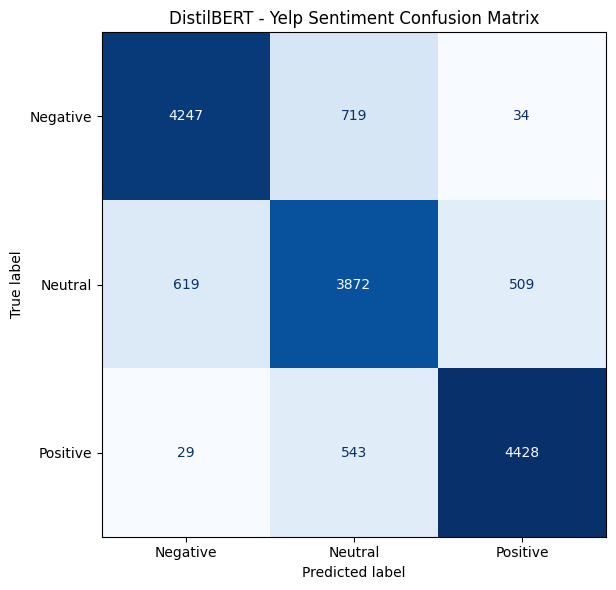

Confusion Matrix generated successfully!


In [44]:

# ==========================================
# CONFUSION MATRIX - FIXED
# ==========================================

import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay
)

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1, 2]
)

print("Confusion Matrix Values:")
display(
    pd.DataFrame(
        cm,
        index=["Actual Negative", "Actual Neutral", "Actual Positive"],
        columns=["Predicted Negative", "Predicted Neutral", "Predicted Positive"]
    )
)

fig, ax = plt.subplots(figsize=(8, 6))

display_matrix = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Neutral", "Positive"]
)

display_matrix.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

plt.title("DistilBERT - Yelp Sentiment Confusion Matrix")
plt.tight_layout()
plt.show()

print("Confusion Matrix generated successfully!")


In [45]:

# ==========================================
# INFERENCE LATENCY
# ==========================================

best_model.eval()

latency_texts = test_df["text"].head(55).tolist()

latencies = []

# Warm-up
for text in latency_texts[:5]:

    inputs = best_tokenizer(
        text,
        return_tensors="pt",
        truncation=True,
        max_length=MAX_LENGTH
    ).to(device)

    with torch.inference_mode():

        _ = best_model(**inputs)

if device.type == "cuda":
    torch.cuda.synchronize()

# Actual measurements
for text in latency_texts[5:]:

    if device.type == "cuda":
        torch.cuda.synchronize()

    start = time.perf_counter()

    inputs = best_tokenizer(
        text,
        return_tensors="pt",
        truncation=True,
        max_length=MAX_LENGTH
    ).to(device)

    with torch.inference_mode():

        _ = best_model(**inputs)

    if device.type == "cuda":
        torch.cuda.synchronize()

    elapsed = time.perf_counter() - start

    latencies.append(elapsed * 1000)

average_latency_ms = float(np.mean(latencies))
median_latency_ms = float(np.median(latencies))

# Parameter count
total_parameters = sum(
    p.numel()
    for p in best_model.parameters()
)

trainable_parameters = sum(
    p.numel()
    for p in best_model.parameters()
    if p.requires_grad
)

print("INFERENCE PERFORMANCE")
print(f"Average latency: {average_latency_ms:.2f} ms")
print(f"Median latency: {median_latency_ms:.2f} ms")
print(f"Total parameters: {total_parameters:,}")
print(f"Trainable parameters: {trainable_parameters:,}")
print(f"Device: {device}")


INFERENCE PERFORMANCE
Average latency: 6.34 ms
Median latency: 6.06 ms
Total parameters: 66,955,779
Trainable parameters: 66,955,779
Device: cuda


In [46]:

# ==========================================
# SAVE FINAL MODEL AND RESULTS
# ==========================================

import json

# Save training history
training_history_df.to_csv(
    RESULTS_DIR / "pretrained_training_history.csv",
    index=False
)

# Save classification report
report_df.to_csv(
    RESULTS_DIR / "pretrained_classification_report.csv"
)

# Save test predictions
predictions_df = pd.DataFrame({
    "review_id": test_df["review_id"].values,
    "text": test_df["text"].values,
    "true_label": y_true,
    "predicted_label": y_pred,
    "true_sentiment": [
        ID2LABEL[int(x)] for x in y_true
    ],
    "predicted_sentiment": [
        ID2LABEL[int(x)] for x in y_pred
    ]
})

predictions_df.to_csv(
    RESULTS_DIR / "pretrained_test_predictions.csv.gz",
    index=False,
    compression="gzip"
)

# Save confusion matrix
plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Neutral", "Positive"],
    yticklabels=["Negative", "Neutral", "Positive"]
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("DistilBERT Confusion Matrix")

plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "pretrained_confusion_matrix.png",
    dpi=200
)

plt.close()

# Final experiment metadata
pretrained_results = {
    "model_name": MODEL_CHECKPOINT,
    "task": "Yelp Three-Class Sentiment Analysis",

    "dataset": "Yelp Reviews",
    "train_size": len(train_df),
    "validation_size": len(val_df),
    "test_size": len(test_df),

    "num_labels": NUM_LABELS,
    "max_length": MAX_LENGTH,
    "epochs": NUM_EPOCHS,
    "learning_rate": LEARNING_RATE,
    "batch_size": TRAIN_BATCH_SIZE,
    "random_seed": SEED,

    "accuracy": float(test_metrics["accuracy"]),
    "precision_macro": float(test_metrics["precision_macro"]),
    "recall_macro": float(test_metrics["recall_macro"]),
    "f1_macro": float(test_metrics["f1_macro"]),

    "training_time_seconds": float(training_time_seconds),
    "average_inference_latency_ms": average_latency_ms,
    "median_inference_latency_ms": median_latency_ms,

    "total_parameters": int(total_parameters),
    "trainable_parameters": int(trainable_parameters),

    "device": str(device),
    "best_validation_f1": float(best_val_f1)
}

with open(
    RESULTS_DIR / "pretrained_results.json",
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        pretrained_results,
        file,
        indent=4,
        ensure_ascii=False
    )

print("All results saved successfully!")

print("\nSaved model:")
print(BEST_MODEL_DIR)

print("\nSaved results:")
print(RESULTS_DIR)

for file in RESULTS_DIR.iterdir():
    print(file.name)


All results saved successfully!

Saved model:
/content/drive/MyDrive/NLP_Task3/pretrained_model/distilbert_yelp_sentiment_clean

Saved results:
/content/drive/MyDrive/NLP_Task3/results
pretrained_training_history.csv
pretrained_classification_report.csv
pretrained_test_predictions.csv.gz
pretrained_confusion_matrix.png
pretrained_results.json


In [47]:

# ==========================================
# INFERENCE FUNCTION FOR STREAMLIT
# ==========================================

def predict_sentiment(text):

    if not isinstance(text, str) or not text.strip():
        raise ValueError("Please enter a valid review.")

    best_model.eval()

    inputs = best_tokenizer(
        text,
        return_tensors="pt",
        truncation=True,
        max_length=MAX_LENGTH
    ).to(device)

    with torch.inference_mode():

        outputs = best_model(**inputs)

        probabilities = torch.softmax(
            outputs.logits,
            dim=-1
        )[0]

    predicted_id = int(
        torch.argmax(probabilities).item()
    )

    sentiment = ID2LABEL[predicted_id]

    confidence = float(
        probabilities[predicted_id].item()
    )

    return {
        "model": "DistilBERT",
        "sentiment": sentiment,
        "confidence": round(confidence * 100, 2),
        "probabilities": {
            ID2LABEL[i]: round(
                float(probabilities[i].item()) * 100,
                2
            )
            for i in range(NUM_LABELS)
        }
    }


# Test prediction
sample_review = (
    "The food was amazing and the staff were very friendly!"
)

prediction = predict_sentiment(sample_review)

print("Input:", sample_review)
print("\nPrediction:")

for key, value in prediction.items():
    print(f"{key}: {value}")


Input: The food was amazing and the staff were very friendly!

Prediction:
model: DistilBERT
sentiment: positive
confidence: 99.13
probabilities: {'negative': 0.04, 'neutral': 0.83, 'positive': 99.13}
